# Gas Intelligence 360° · Etapa 3: Análises em SQL

Todas as perguntas de negócio são respondidas com SQL direto no Data Warehouse.
As consultas ficam em [`analises.sql`](analises.sql); este notebook as executa, mostra os resultados e interpreta.

Técnicas usadas: `JOIN` entre fatos e dimensões, `CTE (WITH)`, funções de janela (`LAG`, `RANK`, `SUM() OVER`),
agregações condicionais e curva ABC.

In [1]:
import os, sys, subprocess, re, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

REPO_URL = "https://github.com/Brithysetubal/gas-intelligence-360.git"
if "google.colab" in sys.modules:
    if not Path("gas-intelligence-360").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("gas-intelligence-360")
else:
    while not Path("data/raw").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

con = sqlite3.connect("data/dw/gas_dw.db")
IMG = Path("docs/img"); IMG.mkdir(parents=True, exist_ok=True)

# Lê o arquivo .sql e separa cada consulta pelo marcador "-- @nome: descrição"
texto = Path("03_sql/analises.sql").read_text(encoding="utf-8")
CONSULTAS = {}
for bloco in re.split(r"^-- @", texto, flags=re.M)[1:]:
    cabecalho, sql = bloco.split("\n", 1)
    nome, desc = cabecalho.split(":", 1)
    CONSULTAS[nome.strip()] = (desc.strip(), sql.strip())

def q(nome):
    desc, sql = CONSULTAS[nome]
    print(f"▶ {desc}\n")
    print(sql, "\n")
    return pd.read_sql(sql, con)

AZUL, LARANJA, CINZA = "#1f5fa8", "#e8833a", "#9aa5b1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(len(CONSULTAS), "consultas carregadas")

12 consultas carregadas


## 1. Visão geral

In [2]:
q("01_kpis_gerais")

▶ Visão geral do negócio (2024-01 a 2026-10)

SELECT
    COUNT(DISTINCT f.sk_contrato)                                   AS contratos,
    ROUND(SUM(f.volume_m3), 0)                                      AS volume_m3,
    ROUND(SUM(f.valor_fatura_brl), 2)                               AS faturado_brl,
    ROUND(SUM(f.valor_pago_brl), 2)                                 AS recebido_brl,
    ROUND(SUM(f.valor_fatura_brl) - SUM(f.valor_pago_brl), 2)       AS em_aberto_brl,
    ROUND(100.0 * (SUM(f.valor_fatura_brl) - SUM(f.valor_pago_brl))
          / SUM(f.valor_fatura_brl), 2)                             AS inadimplencia_pct,
    ROUND(AVG(CASE WHEN f.dias_atraso IS NOT NULL THEN f.dias_atraso END), 1) AS atraso_medio_dias
FROM fato_faturamento f; 



,contratos,volume_m3,faturado_brl,recebido_brl,em_aberto_brl,inadimplencia_pct,atraso_medio_dias
0,300,2555112.0,11927488.34,10323425.71,1604062.63,13.45,17.8


Em 34 meses a operação faturou **R$ 11,9 milhões** e recebeu **R$ 10,3 milhões**: há **R$ 1,6 milhão em aberto (13,5%)**.
O atraso médio dos pagamentos é de quase **18 dias**.

## 2. Evolução mensal: faturamento × recebimento

In [3]:
mensal = q("02_evolucao_mensal")
mensal.tail(6)

▶ Faturamento x recebimento por mês, com variação mensal (LAG) e acumulado

WITH mensal AS (
    SELECT t.competencia,
           SUM(f.valor_fatura_brl) AS faturado,
           SUM(f.valor_pago_brl)   AS recebido
    FROM fato_faturamento f
    JOIN dim_tempo t USING (sk_tempo)
    GROUP BY t.competencia
)
SELECT competencia,
       ROUND(faturado, 2)                                                  AS faturado_brl,
       ROUND(recebido, 2)                                                  AS recebido_brl,
       ROUND(100.0 * recebido / faturado, 1)                               AS taxa_recebimento_pct,
       ROUND(100.0 * (faturado / LAG(faturado) OVER (ORDER BY competencia) - 1), 1) AS var_faturado_mom_pct,
       ROUND(SUM(faturado) OVER (ORDER BY competencia), 2)                 AS faturado_acumulado_brl
FROM mensal
ORDER BY competencia; 



,competencia,faturado_brl,recebido_brl,taxa_recebimento_pct,var_faturado_mom_pct,faturado_acumulado_brl
28,2026-05,356591.99,322466.35,90.4,-2.1,10208352.95
29,2026-06,353599.19,308216.78,87.2,-0.8,10561952.14
30,2026-07,359009.95,335084.42,93.3,1.5,10920962.09
31,2026-08,316018.99,255503.64,80.9,-12.0,11236981.08
32,2026-09,348098.90,298320.53,85.7,10.2,11585079.98
33,2026-10,342408.36,156475.84,45.7,-1.6,11927488.34


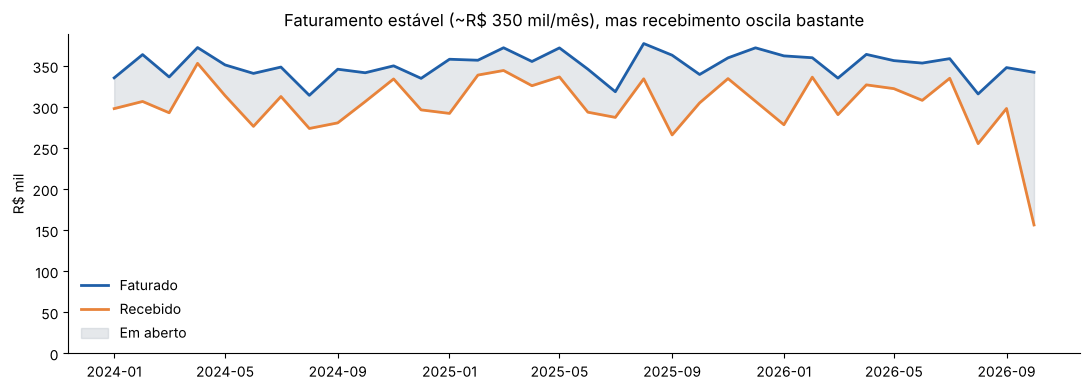

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
x = pd.to_datetime(mensal.competencia)
ax.plot(x, mensal.faturado_brl / 1e3, color=AZUL, lw=2, label="Faturado")
ax.plot(x, mensal.recebido_brl / 1e3, color=LARANJA, lw=2, label="Recebido")
ax.fill_between(x, mensal.recebido_brl / 1e3, mensal.faturado_brl / 1e3, color=CINZA, alpha=0.25, label="Em aberto")
ax.set_ylabel("R$ mil"); ax.set_ylim(0)
ax.set_title("Faturamento estável (~R$ 350 mil/mês), mas recebimento oscila bastante")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); fig.savefig(IMG / "evolucao_mensal.png", dpi=150); plt.show()

- O faturamento é **estável**, entre R$ 315 mil e R$ 377 mil por mês, sem tendência de crescimento.
- A taxa de recebimento oscila entre ~73% e ~95%. Os vales (set/25, jan/26, ago/26) merecem investigação da área de cobrança.
- **Out/2026** aparece com só 46% recebido porque os pagamentos dessa competência tinham data futura e foram para a quarentena: é efeito de corte da base, não de inadimplência real.

## 3. Receita por segmento

In [5]:
seg = q("03_receita_por_segmento")
seg

▶ Participação de cada segmento na receita e no volume

SELECT c.segmento,
       COUNT(DISTINCT f.sk_contrato)                                         AS contratos,
       ROUND(SUM(f.volume_m3), 0)                                            AS volume_m3,
       ROUND(SUM(f.valor_fatura_brl), 2)                                     AS faturado_brl,
       ROUND(100.0 * SUM(f.valor_fatura_brl) / SUM(SUM(f.valor_fatura_brl)) OVER (), 1) AS participacao_receita_pct,
       ROUND(SUM(f.valor_fatura_brl) / COUNT(DISTINCT f.sk_contrato) / COUNT(DISTINCT f.sk_tempo), 2) AS ticket_medio_mensal_brl
FROM fato_faturamento f
JOIN dim_cliente c USING (sk_cliente)
GROUP BY c.segmento
ORDER BY faturado_brl DESC; 



,segmento,contratos,volume_m3,faturado_brl,participacao_receita_pct,ticket_medio_mensal_brl
0,Industrial,18,1874220.0,8059147.03,67.6,13168.54
1,Comercial,62,441785.0,2385636.86,20.0,1131.71
2,Residencial,219,238031.0,1476032.05,12.4,198.23
3,Não identificado,1,1076.0,6672.40,0.1,196.25


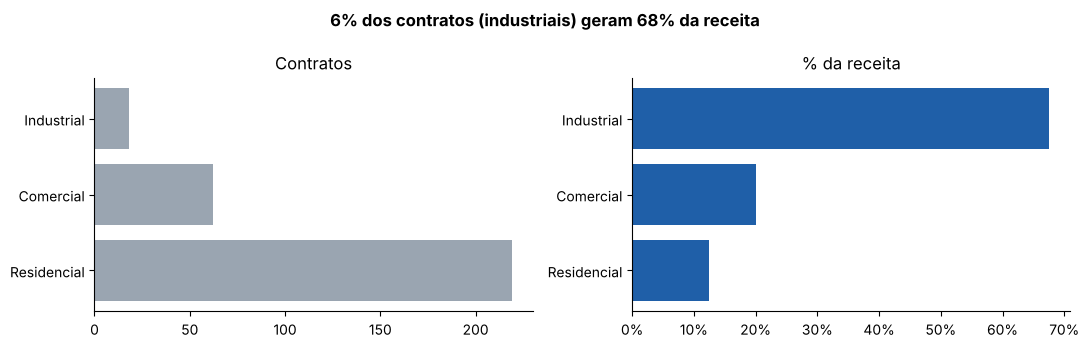

In [6]:
seg3 = seg[seg.segmento != "Não identificado"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].barh(seg3.segmento, seg3.contratos, color=CINZA); axes[0].set_title("Contratos")
axes[1].barh(seg3.segmento, seg3.participacao_receita_pct, color=AZUL); axes[1].set_title("% da receita")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
for a in axes: a.invert_yaxis()
fig.suptitle("6% dos contratos (industriais) geram 68% da receita", fontweight="bold")
plt.tight_layout(); fig.savefig(IMG / "receita_segmento.png", dpi=150); plt.show()

A receita é **muito concentrada**: apenas **18 clientes industriais** respondem por **67,6%** do faturamento,
com ticket médio de R$ 13 mil/mês (66× o residencial). Perder um único cliente industrial equivale a perder ~66 residenciais.

## 4. Curva ABC de clientes

In [7]:
q("08_curva_abc_clientes")

▶ Curva ABC (Pareto) de clientes por receita

WITH receita AS (
    SELECT sk_cliente, SUM(valor_fatura_brl) AS faturado
    FROM fato_faturamento
    GROUP BY sk_cliente
), acumulado AS (
    SELECT sk_cliente, faturado,
           100.0 * SUM(faturado) OVER (ORDER BY faturado DESC ROWS UNBOUNDED PRECEDING)
                 / SUM(faturado) OVER () AS pct_acumulado
    FROM receita
), classificado AS (
    SELECT *, CASE WHEN pct_acumulado <= 80 THEN 'A'
                   WHEN pct_acumulado <= 95 THEN 'B'
                   ELSE 'C' END AS classe
    FROM acumulado
)
SELECT classe,
       COUNT(*)                                            AS clientes,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)  AS pct_clientes,
       ROUND(SUM(faturado), 2)                             AS faturado_brl,
       ROUND(100.0 * SUM(faturado) / SUM(SUM(faturado)) OVER (), 1) AS pct_receita
FROM classificado
GROUP BY classe
ORDER BY classe; 



,classe,clientes,pct_clientes,faturado_brl,pct_receita
0,A,55,18.3,9541421.40,80.0
1,B,152,50.7,1785949.81,15.0
2,C,93,31.0,600117.13,5.0


**18% dos clientes (classe A) concentram 80% da receita**, um Pareto clássico. Esses 55 clientes devem ter
atendimento e cobrança dedicados.

## 5. Inadimplência

In [8]:
cid = q("04_inadimplencia_por_cidade")
cid

▶ Valor em aberto e % de inadimplência por cidade

SELECT ci.cidade,
       COUNT(*)                                                         AS faturas,
       ROUND(SUM(f.valor_fatura_brl), 2)                                AS faturado_brl,
       ROUND(SUM(f.valor_fatura_brl - f.valor_pago_brl), 2)             AS em_aberto_brl,
       ROUND(100.0 * SUM(f.valor_fatura_brl - f.valor_pago_brl) / SUM(f.valor_fatura_brl), 2) AS inadimplencia_pct,
       SUM(f.status_pagamento = 'Em aberto')                            AS faturas_em_aberto
FROM fato_faturamento f
JOIN dim_cidade ci USING (sk_cidade)
GROUP BY ci.cidade
ORDER BY inadimplencia_pct DESC; 



,cidade,faturas,faturado_brl,em_aberto_brl,inadimplencia_pct,faturas_em_aberto
0,Não informado,34,36256.28,7784.86,21.47,7
1,São Gonçalo,1666,1489253.29,263378.95,17.69,211
2,Niterói,1802,2286215.22,331039.29,14.48,225
3,Rio de Janeiro,1292,1829694.81,252205.93,13.78,179
4,Nova Iguaçu,2074,1609311.97,216793.38,13.47,281
5,Petrópolis,1870,3225048.54,377132.87,11.69,220
6,Duque de Caxias,1428,1445035.83,155727.35,10.78,167
7,Desconhecida,34,6672.40,0.00,0.00,0


In [9]:
status = q("05_status_pagamento")
status

▶ Distribuição das faturas por situação de pagamento

SELECT status_pagamento,
       COUNT(*)                                             AS faturas,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)   AS pct_faturas,
       ROUND(SUM(valor_fatura_brl), 2)                      AS faturado_brl
FROM fato_faturamento
GROUP BY status_pagamento
ORDER BY faturas DESC; 



,status_pagamento,faturas,pct_faturas,faturado_brl
0,Pago com atraso,7266,71.2,8656648.96
1,Em aberto,1290,12.6,1517512.94
2,Pago no prazo,1233,12.1,1464828.04
3,Pago parcial,377,3.7,288498.40
4,Sem cobrança,34,0.3,0.00


In [10]:
q("06_atraso_por_meio_pagamento")

▶ Pix x Boleto: atraso médio e % pago no prazo

SELECT meio_pagamento,
       COUNT(*)                                                              AS pagamentos,
       ROUND(AVG(dias_atraso), 1)                                            AS atraso_medio_dias,
       ROUND(100.0 * SUM(dias_atraso <= 0) / COUNT(*), 1)                    AS pago_no_prazo_pct,
       ROUND(100.0 * SUM(status_pagamento = 'Pago parcial') / COUNT(*), 1)   AS pago_parcial_pct
FROM fato_faturamento
WHERE meio_pagamento IS NOT NULL
GROUP BY meio_pagamento; 



,meio_pagamento,pagamentos,atraso_medio_dias,pago_no_prazo_pct,pago_parcial_pct
0,Boleto,3965,17.8,14.3,4.4
1,Pix,4911,17.8,14.7,4.1


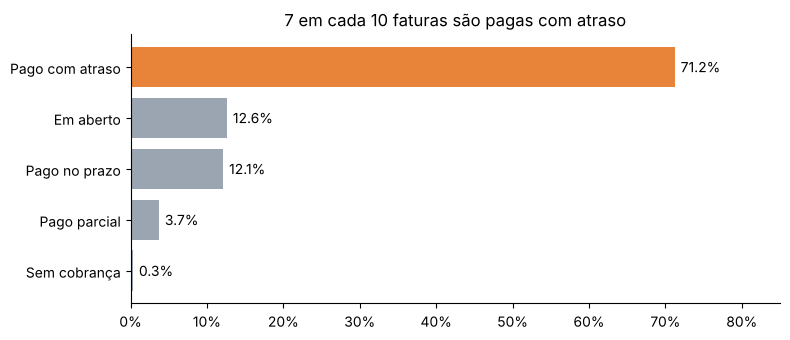

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
s = status.sort_values("faturas")
cores = [LARANJA if v == "Pago com atraso" else CINZA for v in s.status_pagamento]
ax.barh(s.status_pagamento, s.pct_faturas, color=cores)
for i, v in enumerate(s.pct_faturas):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 85)
ax.set_title("7 em cada 10 faturas são pagas com atraso")
plt.tight_layout(); fig.savefig(IMG / "status_pagamento.png", dpi=150); plt.show()

- **71% das faturas são pagas com atraso** e só 12% no prazo. O atraso é a regra, não a exceção.
- **Pix e boleto têm o mesmo comportamento** (atraso médio de 17,8 dias em ambos), então o meio de pagamento não explica o atraso.
  A hipótese a testar é o **vencimento fixo no dia 25**, que pode estar desalinhado com o fluxo de caixa dos clientes.
- **São Gonçalo** tem a maior inadimplência (17,7%), 7 p.p. acima de Duque de Caxias (10,8%).

In [12]:
q("07_top10_devedores")

▶ Ranking dos 10 clientes com maior saldo em aberto

WITH saldo AS (
    SELECT c.cliente_id, c.segmento, ci.cidade,
           SUM(f.valor_fatura_brl - f.valor_pago_brl) AS em_aberto,
           SUM(f.status_pagamento IN ('Em aberto', 'Pago parcial')) AS faturas_pendentes
    FROM fato_faturamento f
    JOIN dim_cliente c USING (sk_cliente)
    JOIN dim_cidade ci ON ci.sk_cidade = f.sk_cidade
    GROUP BY c.cliente_id, c.segmento, ci.cidade
)
SELECT RANK() OVER (ORDER BY em_aberto DESC) AS posicao,
       cliente_id, segmento, cidade,
       ROUND(em_aberto, 2) AS em_aberto_brl,
       faturas_pendentes
FROM saldo
ORDER BY em_aberto DESC
LIMIT 10; 



,posicao,cliente_id,segmento,cidade,em_aberto_brl,faturas_pendentes
0,1,CLI0279,Industrial,São Gonçalo,136593.96,10
1,2,CLI0278,Industrial,Niterói,90661.85,8
2,3,CLI0287,Industrial,Rio de Janeiro,88616.00,6
3,4,CLI0030,Industrial,Rio de Janeiro,72092.46,6
4,5,CLI0011,Industrial,Nova Iguaçu,64301.39,6
5,6,CLI0186,Industrial,Niterói,61862.25,7
6,7,CLI0266,Industrial,Petrópolis,61216.85,5
7,8,CLI0252,Industrial,Petrópolis,57212.68,5
8,9,CLI0243,Industrial,Petrópolis,56537.99,5
9,10,CLI0215,Industrial,Petrópolis,56344.66,6


Os 10 maiores saldos em aberto são **todos industriais** e somam cerca de R$ 745 mil, quase metade do valor em aberto.
Uma régua de cobrança focada só nesses 10 clientes já teria grande impacto.

## 6. Operação: perda técnica

In [13]:
perda = q("09_perda_tecnica_por_cidade")
perda

▶ Gás distribuído que não chegou ao medidor + custo por m³

SELECT ci.cidade,
       ROUND(SUM(o.volume_distribuido_m3), 0)                                  AS distribuido_m3,
       ROUND(SUM(o.volume_medido_m3), 0)                                       AS medido_m3,
       ROUND(100.0 * SUM(o.perda_m3) / SUM(o.volume_distribuido_m3), 2)        AS perda_pct,
       ROUND(SUM(o.custo_operacional_brl) / SUM(o.volume_medido_m3), 2)        AS custo_por_m3_medido_brl
FROM fato_operacao o
JOIN dim_cidade ci USING (sk_cidade)
GROUP BY ci.cidade
ORDER BY perda_pct DESC; 



,cidade,distribuido_m3,medido_m3,perda_pct,custo_por_m3_medido_brl
0,Nova Iguaçu,358690.0,323273.0,9.87,2.83
1,Rio de Janeiro,429924.0,391969.0,8.83,2.83
2,São Gonçalo,336614.0,307401.0,8.68,2.85
3,Niterói,517883.0,472986.0,8.67,2.90
4,Petrópolis,773899.0,709137.0,8.37,2.84
5,Duque de Caxias,327053.0,302993.0,7.36,2.95


In [14]:
q("10_perda_por_ano")

▶ Tendência da perda técnica ao longo dos anos

SELECT t.ano,
       ROUND(100.0 * SUM(o.perda_m3) / SUM(o.volume_distribuido_m3), 2) AS perda_pct,
       ROUND(SUM(o.custo_operacional_brl), 2)                           AS custo_operacional_brl
FROM fato_operacao o
JOIN dim_tempo t USING (sk_tempo)
GROUP BY t.ano
ORDER BY t.ano; 



,ano,perda_pct,custo_operacional_brl
0,2024,9.12,2535268.81
1,2025,8.57,2570841.02
2,2026,8.06,2067136.10


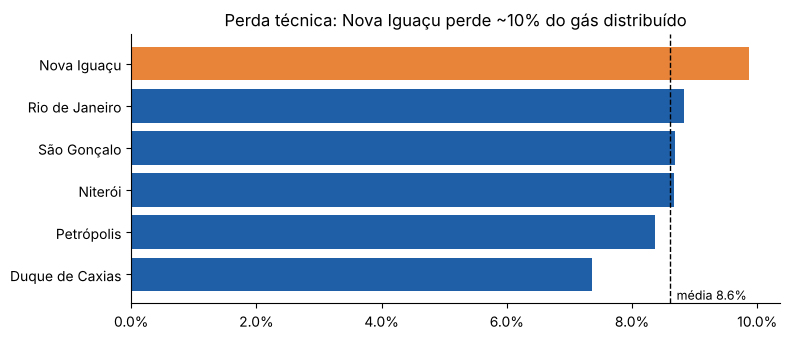

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5))
p = perda.sort_values("perda_pct")
media = 100 * (perda.distribuido_m3.sum() - perda.medido_m3.sum()) / perda.distribuido_m3.sum()
ax.barh(p.cidade, p.perda_pct, color=[LARANJA if v == p.perda_pct.max() else AZUL for v in p.perda_pct])
ax.axvline(media, color="black", ls="--", lw=1); ax.text(media + 0.1, -0.6, f"média {media:.1f}%", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Perda técnica: Nova Iguaçu perde ~10% do gás distribuído")
plt.tight_layout(); fig.savefig(IMG / "perda_tecnica.png", dpi=150); plt.show()

- Em média **~8,6% do gás distribuído não chega ao medidor**. Nova Iguaçu lidera (9,9%).
- A perda **vem caindo**: 9,1% em 2024 → 8,1% em 2026, sinal de que ações de manutenção estão funcionando.

## 7. Ocorrências técnicas e qualidade de leitura

In [16]:
q("11_ocorrencias_tipo_severidade")

▶ Ocorrências por tipo e severidade, com % ainda abertas

SELECT tipo_ocorrencia,
       COUNT(*)                                                    AS total,
       SUM(severidade = 'Alta')                                    AS alta,
       SUM(severidade = 'Média')                                   AS media,
       SUM(severidade = 'Baixa')                                   AS baixa,
       SUM(status_ocorrencia = 'Aberta')                           AS abertas,
       ROUND(100.0 * SUM(status_ocorrencia = 'Aberta') / COUNT(*), 1) AS abertas_pct
FROM fato_ocorrencia
GROUP BY tipo_ocorrencia
ORDER BY total DESC; 



,tipo_ocorrencia,total,alta,media,baixa,abertas,abertas_pct
0,Vazamento reportado,40,9,16,15,5,12.5
1,Manutenção,39,12,12,15,4,10.3
2,Falha de medição,37,14,11,12,3,8.1
3,Interrupção,34,9,9,16,4,11.8


In [17]:
q("12_qualidade_leitura")

▶ Leituras inválidas por tipo de leitura (manual x automática)

SELECT tipo_leitura,
       COUNT(*)                                                         AS leituras,
       SUM(status_leitura <> 'Válida')                                  AS invalidas,
       ROUND(100.0 * SUM(status_leitura <> 'Válida') / COUNT(*), 2)     AS invalidas_pct
FROM fato_faturamento
WHERE tipo_leitura IS NOT NULL
GROUP BY tipo_leitura; 



,tipo_leitura,leituras,invalidas,invalidas_pct
0,Automática,5053,19,0.38
1,Manual,5147,16,0.31


- **Vazamentos** são o tipo mais frequente (40) e têm a maior proporção ainda em aberto (12,5%): prioridade de segurança.
- **Falha de medição** concentra a maior quantidade de casos de severidade alta (14).
- Leituras automáticas e manuais têm taxa de erro parecida (~0,3%), então a automação ainda não trouxe ganho de qualidade.

In [18]:
con.close()

✅ Próxima etapa: **[04 · Dashboard no Power BI](../04_power_bi/README.md)**.